# TRUSTSR Lab 02.03 — Signed Checkpoint Manifest and Signature Verification

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.02
Lab 02.02 used SHA-256 digests and provenance labels. A digest detects accidental or unauthorized content changes only if the expected digest is protected; a plain provenance label is not proof of identity. This lab adds a digital signature over a canonical checkpoint manifest.

## What this notebook demonstrates
1. Create a checkpoint manifest containing state IDs, values, versions, and provenance labels.
2. Generate a temporary signing key pair for this notebook session.
3. Sign the canonical manifest with the private key.
4. Verify the signature using the public key before restoring.
5. Test payload tampering, signature tampering, manifest alteration, and use of a wrong public key.
6. Compare unsigned/unverified restore with signature-gated restore.
7. Export record-level decisions and scenario-level metrics to CSV.

## Security and evidence boundary
This is a **local synthetic demonstration**. It does not provide production key storage, key rotation, revocation, hardware-backed signing, secure timestamping, or an independently trusted public-key distribution mechanism. If an attacker can replace both the manifest and the public key, signature verification alone does not help; the verifier must already trust the public key.

All outcomes are synthetic. Passing assertions demonstrates only that the implemented test cases behave as specified, not that TRUSTSR is production-secure.

## 1. Install and import dependencies

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
import sys
import platform
import json
import copy
import base64
import hashlib
from datetime import datetime, timezone

import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.hazmat.primitives import serialization
from cryptography.exceptions import InvalidSignature

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("cryptography:", __import__("cryptography").__version__)
print("Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
cryptography: 46.0.6
Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:32.557694+00:00
Evidence type: synthetic simulation only


## 2. Create a canonical checkpoint manifest

In [3]:
checkpoint_values = {
    "M1": "approved project requirement",
    "M2": "safe planning memory",
    "D1": "plan based on approved requirement",
    "P1": "execution plan derived from D1",
    "A1": "draft action derived from P1",
    "S1": "independent status note",
}

def canonical_manifest_bytes(manifest):
    # Stable serialization is required: same logical manifest -> same bytes.
    return json.dumps(
        manifest, sort_keys=True, separators=(",", ":"), ensure_ascii=False
    ).encode("utf-8")

def make_manifest(values):
    return {
        "schema_version": 1,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "states": [
            {
                "state_id": state_id,
                "version": 1,
                "value": value,
                "provenance": "synthetic_trusted_writer",
            }
            for state_id, value in sorted(values.items())
        ],
    }

manifest = make_manifest(checkpoint_values)
manifest_bytes = canonical_manifest_bytes(manifest)
print("Manifest state records:", len(manifest["states"]))
print("Canonical payload bytes:", len(manifest_bytes))
print("Payload SHA-256:", hashlib.sha256(manifest_bytes).hexdigest())
display(pd.DataFrame(manifest["states"]))

Manifest state records: 6
Canonical payload bytes: 732
Payload SHA-256: dc4c4f44ffccec0043931f278a73602e01c6be6b8e015a49c552ea422d6ab017


  state_id  version                               value                provenance
0       A1        1        draft action derived from P1  synthetic_trusted_writer
1       D1        1  plan based on approved requirement  synthetic_trusted_writer
2       M1        1        approved project requirement  synthetic_trusted_writer
3       M2        1                safe planning memory  synthetic_trusted_writer
4       P1        1      execution plan derived from D1  synthetic_trusted_writer
5       S1        1             independent status note  synthetic_trusted_writer

## 3. Generate a session-only Ed25519 key pair and sign the manifest

In [4]:
# Demonstration only: this private key exists in this notebook runtime.
# Do not use this pattern as production key management.
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()

signature = private_key.sign(manifest_bytes)
public_key_pem = public_key.public_bytes(
    encoding=serialization.Encoding.PEM,
    format=serialization.PublicFormat.SubjectPublicKeyInfo,
)
signature_b64 = base64.b64encode(signature).decode("ascii")

print("Algorithm: Ed25519")
print("Signature bytes:", len(signature))
print("Public key PEM (demo):")
print(public_key_pem.decode("utf-8"))
print("Signature (Base64):", signature_b64)

Algorithm: Ed25519
Signature bytes: 64
Public key PEM (demo):
-----BEGIN PUBLIC KEY-----
MCowBQYDK2VwAyEAdU4Sg3dfFDFJTuSoAnE2apiJMMHh75lT1oVhswpSDPM=
-----END PUBLIC KEY-----

Signature (Base64): xL9oU4gO3sH7qlTlcCzork/da/Oq0xKiFauyoFLLvLOFc9TieuSlhAPVs/RHIMQX9DWYianBPjS46+PA5KTNCA==


## 4. Define signature verification and restore gates

In [5]:
def verify_signature(manifest_obj, signature_bytes, trusted_public_key):
    payload = canonical_manifest_bytes(manifest_obj)
    try:
        trusted_public_key.verify(signature_bytes, payload)
        return {"valid": True, "reason": "signature_valid"}
    except InvalidSignature:
        return {"valid": False, "reason": "invalid_signature"}

def restore_without_signature_gate(manifest_obj):
    # Deliberately unsafe baseline: accepts the payload without verification.
    return {
        "decision": "restored_without_signature_verification",
        "restored_state_count": len(manifest_obj.get("states", [])),
    }

def restore_with_signature_gate(manifest_obj, signature_bytes, trusted_public_key):
    result = verify_signature(manifest_obj, signature_bytes, trusted_public_key)
    if not result["valid"]:
        return {
            "decision": "quarantined_signature_failure",
            "restored_state_count": 0,
            "verification_reason": result["reason"],
        }
    return {
        "decision": "restored_after_signature_verification",
        "restored_state_count": len(manifest_obj.get("states", [])),
        "verification_reason": result["reason"],
    }

valid_check = verify_signature(manifest, signature, public_key)
print("Original manifest verification:", valid_check)
assert valid_check["valid"]

Original manifest verification: {'valid': True, 'reason': 'signature_valid'}


## 5. Construct tampering and key-mismatch scenarios

In [6]:
scenarios = {}

# Control: original manifest and signature.
scenarios["untampered"] = (copy.deepcopy(manifest), signature, public_key)

# Change a state payload but reuse original signature.
payload_tampered = copy.deepcopy(manifest)
payload_tampered["states"][0]["value"] = "TAMPERED: unauthorized instruction"
scenarios["payload_tampered"] = (payload_tampered, signature, public_key)

# Change the manifest metadata while reusing original signature.
metadata_tampered = copy.deepcopy(manifest)
metadata_tampered["schema_version"] = 999
scenarios["metadata_tampered"] = (metadata_tampered, signature, public_key)

# Corrupt the signature bytes.
bad_signature = bytearray(signature)
bad_signature[0] ^= 0x01
scenarios["signature_tampered"] = (copy.deepcopy(manifest), bytes(bad_signature), public_key)

# Verify with a different public key.
wrong_private_key = Ed25519PrivateKey.generate()
wrong_public_key = wrong_private_key.public_key()
scenarios["wrong_public_key"] = (copy.deepcopy(manifest), signature, wrong_public_key)

print("Scenarios:", list(scenarios.keys()))
print("All tampering scenarios are synthetic and deterministic except session-generated keys.")

Scenarios: ['untampered', 'payload_tampered', 'metadata_tampered', 'signature_tampered', 'wrong_public_key']
All tampering scenarios are synthetic and deterministic except session-generated keys.


## 6. Evaluate the scenarios

In [7]:
rows = []
for scenario_name, (manifest_obj, sig, verification_key) in scenarios.items():
    verification = verify_signature(manifest_obj, sig, verification_key)
    ungated = restore_without_signature_gate(manifest_obj)
    gated = restore_with_signature_gate(manifest_obj, sig, verification_key)
    rows.append({
        "scenario": scenario_name,
        "signature_valid": verification["valid"],
        "verification_reason": verification["reason"],
        "ungated_restored_state_count": ungated["restored_state_count"],
        "gated_decision": gated["decision"],
        "gated_restored_state_count": gated["restored_state_count"],
        "blocked_by_gate": gated["restored_state_count"] == 0,
    })

results_df = pd.DataFrame(rows)
display(results_df)

             scenario  signature_valid verification_reason  ungated_restored_state_count                         gated_decision  gated_restored_state_count  blocked_by_gate
0          untampered             True     signature_valid                             6  restored_after_signature_verification                           6            False
1    payload_tampered            False   invalid_signature                             6          quarantined_signature_failure                           0             True
2   metadata_tampered            False   invalid_signature                             6          quarantined_signature_failure                           0             True
3  signature_tampered            False   invalid_signature                             6          quarantined_signature_failure                           0             True
4    wrong_public_key            False   invalid_signature                             6          quarantined_signature_failure        

## 7. Plot gated versus ungated restoration

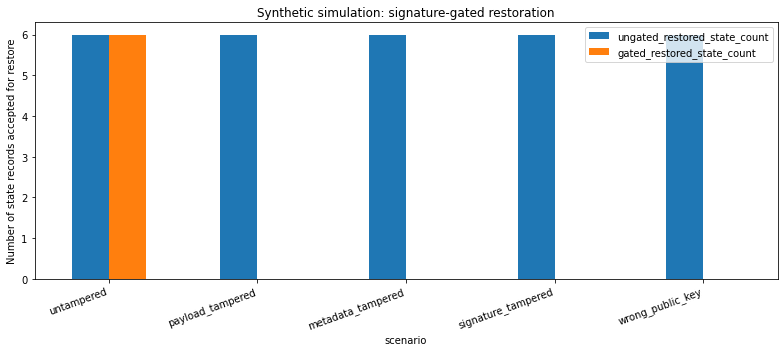

In [8]:
plot_df = results_df.set_index("scenario")[[
    "ungated_restored_state_count", "gated_restored_state_count"
]]
ax = plot_df.plot(kind="bar", figsize=(11, 5))
ax.set_ylabel("Number of state records accepted for restore")
ax.set_title("Synthetic simulation: signature-gated restoration")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 8. Assertions

In [9]:
assert results_df.loc[results_df["scenario"] == "untampered", "signature_valid"].iloc[0]
assert not results_df.loc[results_df["scenario"] != "untampered", "signature_valid"].any()
assert results_df.loc[results_df["scenario"] == "untampered", "gated_restored_state_count"].iloc[0] == len(manifest["states"])
assert (results_df.loc[results_df["scenario"] != "untampered", "gated_restored_state_count"] == 0).all()
assert (results_df.loc[results_df["scenario"] != "untampered", "blocked_by_gate"]).all()

print("PASS: original signed manifest verifies with its trusted public key.")
print("PASS: payload tampering invalidates the signature.")
print("PASS: metadata tampering invalidates the signature.")
print("PASS: signature corruption is rejected.")
print("PASS: wrong public key is rejected.")
print("PASS: all invalid scenarios are blocked from restoration.")
print("All Lab 02.03 assertions passed.")

PASS: original signed manifest verifies with its trusted public key.
PASS: payload tampering invalidates the signature.
PASS: metadata tampering invalidates the signature.
PASS: signature corruption is rejected.
PASS: wrong public key is rejected.
PASS: all invalid scenarios are blocked from restoration.
All Lab 02.03 assertions passed.


## 9. Export CSV and verification artifacts

In [10]:
results_df.to_csv("trustsr_lab02_03_signature_verification_results.csv", index=False)

# Export only public verification material, never export the private key.
with open("trustsr_lab02_03_public_key.pem", "wb") as f:
    f.write(public_key_pem)
with open("trustsr_lab02_03_signature.txt", "w", encoding="utf-8") as f:
    f.write(signature_b64)
with open("trustsr_lab02_03_canonical_manifest.json", "wb") as f:
    f.write(manifest_bytes)

print("Generated files:")
print("- trustsr_lab02_03_signature_verification_results.csv")
print("- trustsr_lab02_03_public_key.pem")
print("- trustsr_lab02_03_signature.txt")
print("- trustsr_lab02_03_canonical_manifest.json")
print("Security note: the private key is intentionally not exported.")

Generated files:
- trustsr_lab02_03_signature_verification_results.csv
- trustsr_lab02_03_public_key.pem
- trustsr_lab02_03_signature.txt
- trustsr_lab02_03_canonical_manifest.json
Security note: the private key is intentionally not exported.


## 10. Interpretation and limitations

### What this prototype demonstrates
Within the controlled notebook, Ed25519 signature verification accepts the original manifest when paired with the corresponding public key and rejects payload changes, metadata changes, corrupted signatures, and a mismatched public key.

### Critical limitations
- The public key is trusted because the notebook already holds the corresponding key object. Public-key authenticity/distribution is not solved.
- The private key is generated in a temporary runtime and is not securely managed, rotated, or revoked.
- The notebook does not protect against compromise of the signing process or host.
- No trusted timestamp, append-only audit log, remote attestation, or external-effect compensation is implemented.
- The dataset and scenarios are synthetic; this is not production validation or a formal proof of TRUSTSR.

### Next research step
Lab 02.04 should introduce version/rollback protection and replay tests: reject an older but correctly signed checkpoint when a newer trusted version is required. Continue to label results as synthetic simulation.